# RQ3: Laboratory Mobility Clustering

Stages 2 and 3: label-blind K-means clustering and Gaussian mixture modeling. Fall-history fields are not included in the clustering matrix.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency, fisher_exact

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'Clustering':
    PROJECT_ROOT = PROJECT_ROOT.parents[1]

LAB_FEATURES_PATH = PROJECT_ROOT / 'Data/Clustering/Lab/lab_participant_features.csv'
ASSIGNMENTS_PATH = PROJECT_ROOT / 'Data/Clustering/Lab/lab_cluster_assignments_stage2.csv'
HOME_FEATURES_PATH = PROJECT_ROOT / 'Data/Clustering/Home/home_participant_features.csv'
HOME_ASSIGNMENTS_PATH = PROJECT_ROOT / 'Data/Clustering/Home/home_cluster_assignments_stage6.csv'
FALL_HISTORY_PATH = PROJECT_ROOT / 'Data/lab/4 Test Classification(4 Test Classification).csv'
ASSOCIATION_PATH = PROJECT_ROOT / 'Data/Clustering/Lab/lab_fall_history_association.csv'

PRIMARY_FEATURE_COLUMNS = [
    'walk_cadence_steps_min',
    'pooled_median_turn_duration_s',
    'pooled_median_turn_step_count',
    'sit_to_stand_duration_s',
]

# Task-derived sacrum outcomes. Left and right turn trials are pooled into
# participant-level turn features so a missing turn direction does not
# remove a participant with valid data for the opposite direction.
ALL_SACRUM_FEATURE_COLUMNS = [
    'median_sacrum_walk_duration_s',
    'median_sacrum_walk_cadence_steps_min',
    'median_sacrum_walk_mean_step_time_s',
    'pooled_median_turn_duration_s',
    'pooled_median_turn_step_count',
    'median_sacrum_sit_to_stand_duration_s',
]

# Change to 'primary' to restore the original four-feature analysis.
FEATURE_SET = 'all_sacrum'
FEATURE_COLUMNS = (
    ALL_SACRUM_FEATURE_COLUMNS if FEATURE_SET == 'all_sacrum'
    else PRIMARY_FEATURE_COLUMNS
)
PLOT_CADENCE_COLUMN = 'walk_cadence_steps_min'
PLOT_TURN_DURATION_COLUMN = 'pooled_median_turn_duration_s'
HOME_FEATURE_MAP = {
    'walk_cadence_steps_min': 'walk_cadence_steps_min',
    'pooled_median_turn_duration_s': 'pooled_median_turn_duration_s',
    'pooled_median_turn_step_count': 'pooled_median_turn_step_count',
    'sit_to_stand_duration_s': 'sit_to_stand_duration_s',
    'median_sacrum_walk_duration_s': 'median_walk_duration',
    'median_sacrum_walk_cadence_steps_min': 'walk_cadence_steps_min',
    'median_sacrum_walk_mean_step_time_s': 'median_mean_step_time',
    'median_sacrum_sit_to_stand_duration_s': 'median_sit_to_stand_duration',
}
RANDOM_STATE = 42
N_CLUSTERS = 2

In [2]:
lab = pd.read_csv(LAB_FEATURES_PATH)
display_columns = ['subject_id', PLOT_CADENCE_COLUMN, PLOT_TURN_DURATION_COLUMN]
analysis = lab[[*dict.fromkeys([*display_columns, *FEATURE_COLUMNS])]].dropna(subset=FEATURE_COLUMNS).copy()

# Fall-history columns are deliberately excluded from X.
X = analysis[FEATURE_COLUMNS]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Feature set: {FEATURE_SET} ({len(FEATURE_COLUMNS)} features)')
print(f'Participants used: {len(analysis)}')
display(analysis)

Feature set: all_sacrum (6 features)
Participants used: 16


,subject_id,walk_cadence_steps_min,pooled_median_turn_duration_s,median_sacrum_walk_duration_s,median_sacrum_walk_cadence_steps_min,median_sacrum_walk_mean_step_time_s,pooled_median_turn_step_count,median_sacrum_sit_to_stand_duration_s
0,SRS02,83.631,4.520,7.175,83.631,0.718,5.5,0.830
1,SRS03,80.108,7.230,7.490,80.108,0.749,7.5,0.170
2,SRS04,69.767,9.260,8.600,69.767,0.860,11.0,2.740
3,SRS05,94.044,6.530,6.380,94.044,0.638,8.0,1.710
4,SRS06,80.429,4.160,7.460,80.429,0.746,4.0,1.640
5,SRS07,60.706,9.030,9.890,60.706,0.989,11.0,1.315
6,SRS08,84.632,4.985,7.090,84.632,0.709,6.0,1.135
7,SRS09,112.466,3.290,5.335,112.466,0.534,4.0,1.340
8,SRS10,92.575,4.205,6.835,92.575,0.683,5.5,1.710
9,SRS12,83.765,8.695,7.175,83.765,0.718,10.0,1.215


In [3]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=100, random_state=RANDOM_STATE)
analysis['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

cluster_profiles = analysis.groupby('kmeans_cluster')[FEATURE_COLUMNS].agg(['mean', 'median', 'count']).round(3)
assignments = analysis[['subject_id', 'kmeans_cluster']].sort_values('subject_id')
assignments.to_csv(ASSIGNMENTS_PATH, index=False)

print('K-means cluster sizes')
display(analysis['kmeans_cluster'].value_counts().sort_index().rename('n').to_frame())
print('Participant assignments')
display(assignments)
print('Cluster profiles')
display(cluster_profiles)

K-means cluster sizes


,n
kmeans_cluster,
0,7
1,9


Participant assignments


,subject_id,kmeans_cluster
0,SRS02,0
1,SRS03,1
2,SRS04,1
3,SRS05,0
4,SRS06,0
5,SRS07,1
6,SRS08,0
7,SRS09,0
8,SRS10,0
9,SRS12,1


Cluster profiles


median_sacrum_walk_duration_s               \
                                        mean median count   
kmeans_cluster                                              
0                                      6.598  6.835     7   
1                                      8.057  7.660     9   

               median_sacrum_walk_cadence_steps_min                \
                                               mean  median count   
kmeans_cluster                                                      
0                                            92.757  92.575     7   
1                                            75.161  78.329     9   

               median_sacrum_walk_mean_step_time_s               \
                                              mean median count   
kmeans_cluster                                                    
0                                            0.660  0.683     7   
1                                            0.806  0.766     9   

               pooled_median_turn_duration_s               \
                                        mean median count   
kmeans_cluster                                              
0                                      4.571  4.305     7   
1                                      9.527  9.030     9   

               pooled_median_turn_step_count               \
                                        mean median count   
kmeans_cluster                                              
0                                      5.571    5.5     7   
1                                     11.389   11.0     9   

               median_sacrum_sit_to_stand_duration_s               
                                                mean median count  
kmeans_cluster                                                     
0                                              1.438  1.640     7  
1                                              1.329  1.315     9

In [4]:
gmm = GaussianMixture(
    n_components=N_CLUSTERS,
    covariance_type='diag',
    reg_covar=0.10,
    n_init=100,
    random_state=RANDOM_STATE,
)
gmm_probabilities = gmm.fit(X_scaled).predict_proba(X_scaled)
analysis['gmm_cluster'] = gmm_probabilities.argmax(axis=1)
analysis['gmm_membership_probability'] = gmm_probabilities.max(axis=1)
display(pd.crosstab(analysis['kmeans_cluster'], analysis['gmm_cluster'], rownames=['K-means'], colnames=['GMM']))
display(analysis[['subject_id', 'kmeans_cluster', 'gmm_cluster', 'gmm_membership_probability']].sort_values('subject_id'))

# Update the saved Stage 2 assignments without adding any fall-history labels.
analysis[['subject_id', 'kmeans_cluster', 'gmm_cluster', 'gmm_membership_probability']].sort_values('subject_id').to_csv(ASSIGNMENTS_PATH, index=False)

GMM,0,1
K-means,,
0,7,0
1,0,9


,subject_id,kmeans_cluster,gmm_cluster,gmm_membership_probability
0,SRS02,0,0,0.994577
1,SRS03,1,1,0.996908
2,SRS04,1,1,1.000000
3,SRS05,0,0,0.999262
4,SRS06,0,0,0.995338
5,SRS07,1,1,1.000000
6,SRS08,0,0,0.997040
7,SRS09,0,0,1.000000
8,SRS10,0,0,0.999958
9,SRS12,1,1,0.997284


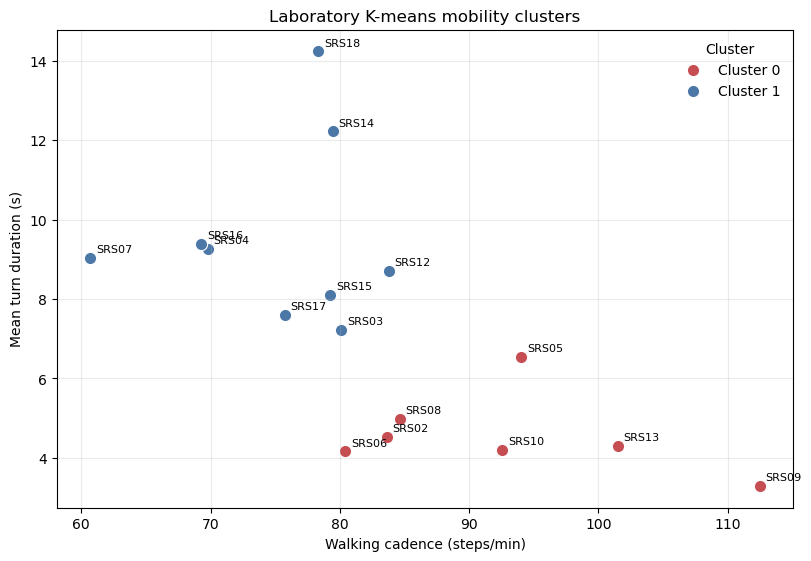

In [5]:
import matplotlib.pyplot as plt

cluster_colors = {0: '#C44E52', 1: '#4C78A8'}
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
for cluster, group in analysis.groupby('kmeans_cluster'):
    ax.scatter(
        group[PLOT_CADENCE_COLUMN],
        group[PLOT_TURN_DURATION_COLUMN],
        s=78,
        color=cluster_colors[cluster],
        label=f'Cluster {cluster}',
        edgecolor='white',
        linewidth=0.8,
    )
    for _, participant in group.iterrows():
        ax.annotate(
            participant['subject_id'],
            (participant[PLOT_CADENCE_COLUMN], participant[PLOT_TURN_DURATION_COLUMN]),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=8,
        )
ax.set_xlabel('Walking cadence (steps/min)')
ax.set_ylabel('Mean turn duration (s)')
ax.set_title('Laboratory K-means mobility clusters')
ax.grid(alpha=0.25)
ax.legend(title='Cluster', frameon=False)
plt.show()

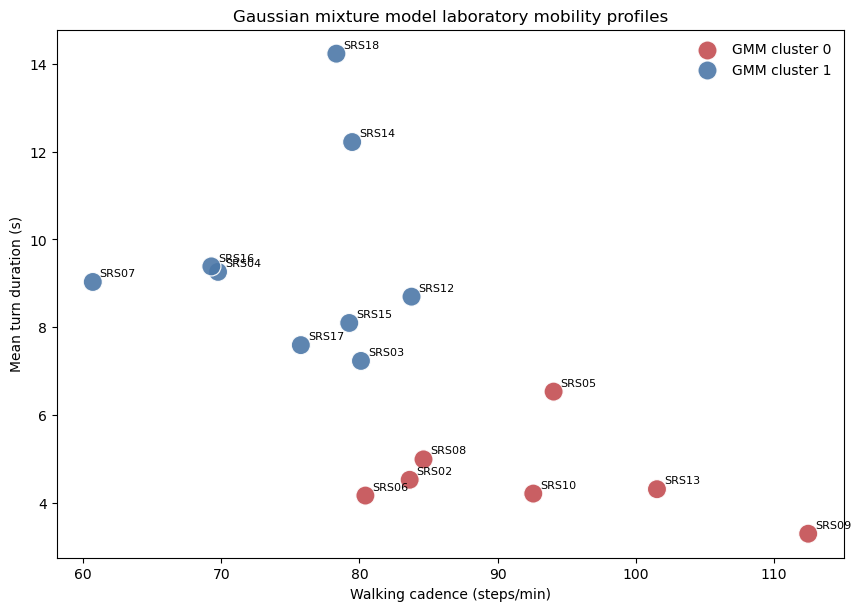

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 6), constrained_layout=True)
for cluster, color in cluster_colors.items():
    subset = analysis[analysis['gmm_cluster'] == cluster]
    ax.scatter(
        subset[PLOT_CADENCE_COLUMN],
        subset[PLOT_TURN_DURATION_COLUMN],
        s=70 + 120 * subset['gmm_membership_probability'],
        color=color,
        edgecolor='white',
        linewidth=0.9,
        alpha=0.9,
        label=f'GMM cluster {cluster}',
    )

for row in analysis.itertuples():
    ax.annotate(
        row.subject_id,
        (getattr(row, PLOT_CADENCE_COLUMN), getattr(row, PLOT_TURN_DURATION_COLUMN)),
        xytext=(5, 4),
        textcoords='offset points',
        fontsize=8,
    )

ax.set_xlabel('Walking cadence (steps/min)')
ax.set_ylabel('Mean turn duration (s)')
ax.set_title('Gaussian mixture model laboratory mobility profiles')
ax.legend(frameon=False, loc='best')
plt.show()

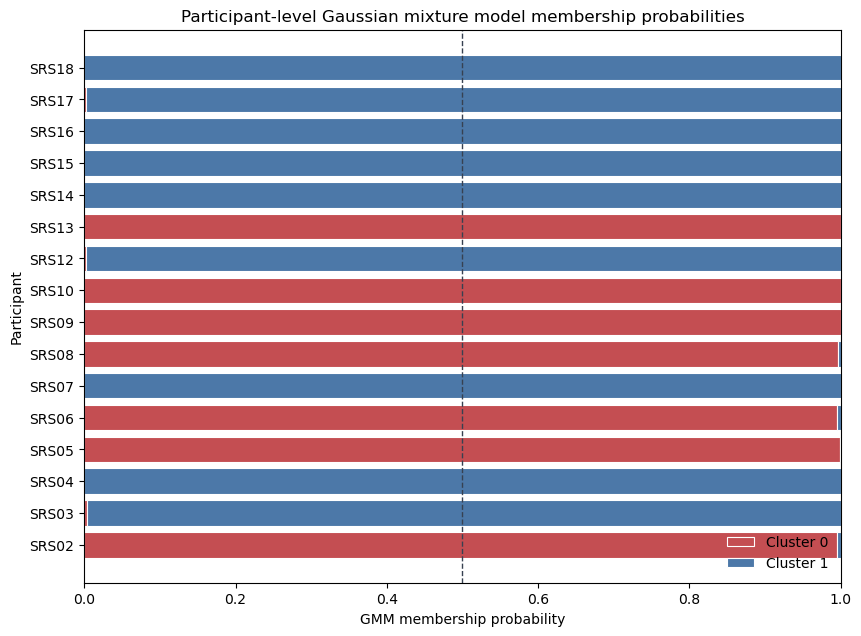

In [7]:
probability_table = pd.DataFrame({
    'subject_id': analysis['subject_id'],
    'Cluster 0': gmm_probabilities[:, 0],
    'Cluster 1': gmm_probabilities[:, 1],
}).sort_values('subject_id')

fig, ax = plt.subplots(figsize=(8.5, 6.25), constrained_layout=True)
left = pd.Series(0.0, index=probability_table.index)
for cluster, color in cluster_colors.items():
    column = f'Cluster {cluster}'
    ax.barh(
        probability_table['subject_id'],
        probability_table[column],
        left=left,
        color=color,
        edgecolor='white',
        linewidth=0.8,
        label=column,
    )
    left += probability_table[column]

ax.axvline(0.50, color='#374151', linestyle='--', linewidth=1.0)
ax.set_xlim(0, 1)
ax.set_xlabel('GMM membership probability')
ax.set_ylabel('Participant')
ax.set_title('Participant-level Gaussian mixture model membership probabilities')
ax.legend(frameon=False, loc='lower right')
plt.show()


## Stage 4: Laboratory Cluster Association With Final Classification

Final faller and non-faller classifications are joined only after the unsupervised laboratory clusters have been fixed. They are not used to fit, select, or relabel the K-means or Gaussian mixture models. The primary association test is Fisher's exact test because of the small two-by-two table. Phi is reported as a descriptive measure of association.

In [8]:
final_labels = pd.read_csv(FALL_HISTORY_PATH)[
    ['Participant ID', 'Final Classification']
].dropna().drop_duplicates('Participant ID')

final_labels = final_labels.rename(columns={
    'Participant ID': 'subject_id',
    'Final Classification': 'final_classification',
})
association = analysis.merge(final_labels, on='subject_id', how='inner')
association = association[[
    'subject_id', 'kmeans_cluster', 'gmm_cluster',
    'gmm_membership_probability', 'final_classification',
]].sort_values('subject_id')

if len(association) != len(analysis):
    missing_labels = sorted(set(analysis['subject_id']) - set(association['subject_id']))
    print('Participants without a final-classification label:', missing_labels)

association.to_csv(ASSOCIATION_PATH, index=False)
display(association)


,subject_id,kmeans_cluster,gmm_cluster,gmm_membership_probability,final_classification
0,SRS02,0,0,0.994577,Non-Faller
1,SRS03,1,1,0.996908,Faller
2,SRS04,1,1,1.000000,Non-Faller
3,SRS05,0,0,0.999262,Non-Faller
4,SRS06,0,0,0.995338,Non-Faller
5,SRS07,1,1,1.000000,Faller
6,SRS08,0,0,0.997040,Non-Faller
7,SRS09,0,0,1.000000,Non-Faller
8,SRS10,0,0,0.999958,Non-Faller
9,SRS12,1,1,0.997284,Faller


In [9]:
fall_order = ['Faller', 'Non-Faller']
contingency = pd.crosstab(
    association['kmeans_cluster'],
    association['final_classification'],
).reindex(index=range(N_CLUSTERS), columns=fall_order, fill_value=0)
contingency.index.name = 'K-means cluster'

fisher_odds_ratio, fisher_p_value = fisher_exact(contingency.to_numpy())
chi_square, _, _, _ = chi2_contingency(contingency.to_numpy(), correction=False)
phi = (chi_square / len(association)) ** 0.5
gmm_contingency = pd.crosstab(
    association['gmm_cluster'],
    association['final_classification'],
).reindex(index=range(N_CLUSTERS), columns=fall_order, fill_value=0)
_, gmm_fisher_p_value = fisher_exact(gmm_contingency.to_numpy())
gmm_chi_square, _, _, _ = chi2_contingency(gmm_contingency.to_numpy(), correction=False)
gmm_phi = (gmm_chi_square / len(association)) ** 0.5

display(contingency)
print(f'Participants with both data sources: {len(association)}')
print(f"Fisher's exact test p-value: {fisher_p_value:.3f}")
print(f'Phi coefficient: {phi:.3f}')


final_classification,Faller,Non-Faller
K-means cluster,,
0,1,6
1,8,1


Participants with both data sources: 16
Fisher's exact test p-value: 0.009
Phi coefficient: 0.746


In [10]:
statistics_table = pd.DataFrame([
    {
        'Model': 'K-means',
        'Participants': len(association),
        "Fisher's exact test": f"p = {fisher_p_value:.3f}",
        'Phi correlation coefficient': f"{phi:.3f}",
    },
    {
        'Model': 'GMM',
        'Participants': len(association),
        "Fisher's exact test": f"p = {gmm_fisher_p_value:.3f}",
        'Phi correlation coefficient': f"{gmm_phi:.3f}",
    },
])
display(statistics_table)


,Model,Participants,Fisher's exact test,Phi correlation coefficient
0,K-means,16,p = 0.009,0.746
1,GMM,16,p = 0.009,0.746


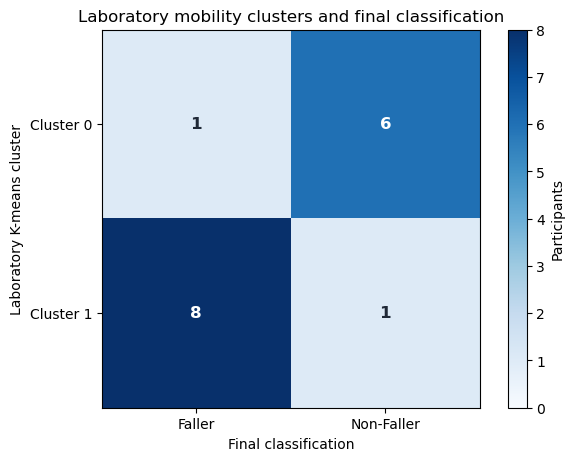

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 4.5), constrained_layout=True)
image = ax.imshow(contingency.to_numpy(), cmap='Blues', vmin=0)
ax.set_xticks(range(len(fall_order)), fall_order)
ax.set_yticks(range(N_CLUSTERS), [f'Cluster {cluster}' for cluster in range(N_CLUSTERS)])
ax.set_xlabel('Final classification')
ax.set_ylabel('Laboratory K-means cluster')
ax.set_title('Laboratory mobility clusters and final classification')

for row_index in range(contingency.shape[0]):
    for column_index in range(contingency.shape[1]):
        ax.text(
            column_index,
            row_index,
            str(contingency.iat[row_index, column_index]),
            ha='center',
            va='center',
            color='white' if contingency.iat[row_index, column_index] >= 4 else '#1F2937',
            fontsize=12,
            fontweight='bold',
        )
fig.colorbar(image, ax=ax, label='Participants')
plt.show()


## PCA variance summary

PCA is fitted to the same standardized laboratory feature matrix used for clustering. The table shows how many components are needed to retain common proportions of the feature information.

In [12]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_scaled)
explained_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = explained_variance.cumsum()

pca_variance_table = pd.DataFrame({
    'Principal component': [f'PC{i}' for i in range(1, len(explained_variance) + 1)],
    'Explained variance (%)': explained_variance,
    'Cumulative variance (%)': cumulative_variance,
}).round(2)

pca_retention_summary = pd.DataFrame([
    {
        'Variance retained': f'{threshold}%',
        'Components required': int((cumulative_variance < threshold).sum() + 1),
    }
    for threshold in (80, 90, 95)
])

display(pca_variance_table)
display(pca_retention_summary)


,Principal component,Explained variance (%),Cumulative variance (%)
0,PC1,65.57,65.57
1,PC2,19.57,85.15
2,PC3,14.14,99.28
3,PC4,0.50,99.78
4,PC5,0.22,100.00
5,PC6,0.00,100.00


,Variance retained,Components required
0,80%,2
1,90%,3
2,95%,3


## Two-component PCA view of laboratory clusters

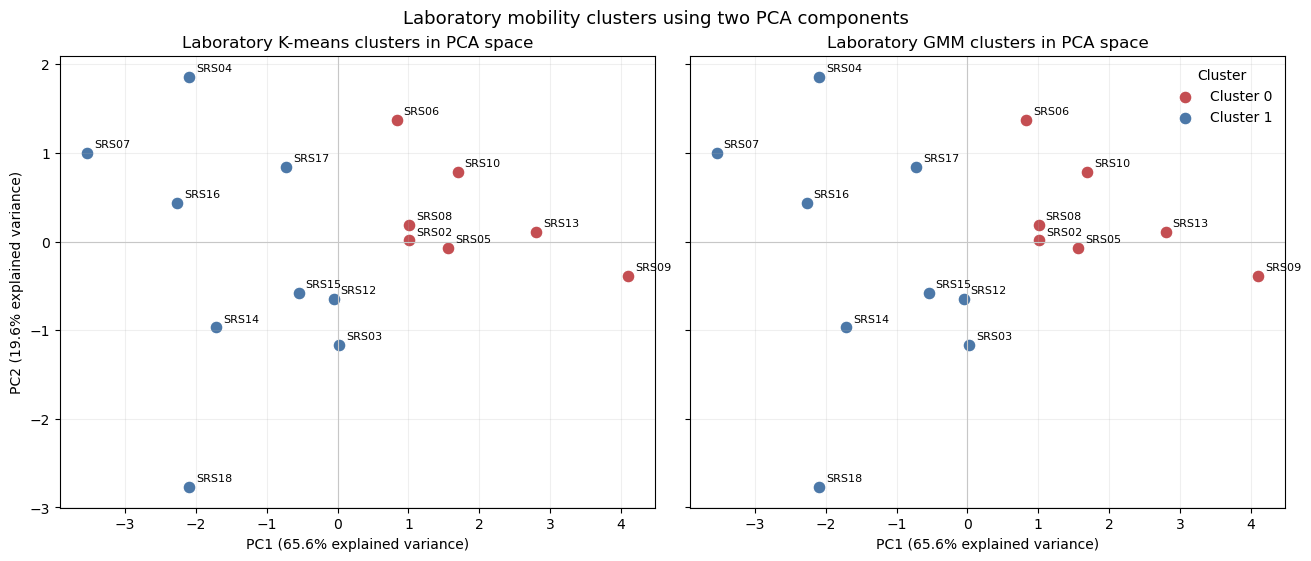

In [13]:
pca_two_components = PCA(n_components=2).fit_transform(X_scaled)
pc1_variance, pc2_variance = explained_variance[:2]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True, constrained_layout=True)
models = [('K-means', 'kmeans_cluster'), ('GMM', 'gmm_cluster')]
for ax, (model_name, cluster_column) in zip(axes, models):
    for cluster, color in cluster_colors.items():
        mask = analysis[cluster_column].to_numpy() == cluster
        ax.scatter(
            pca_two_components[mask, 0], pca_two_components[mask, 1],
            s=85, color=color, edgecolor='white', linewidth=.8,
            label=f'Cluster {cluster}',
        )
    for point, participant in zip(pca_two_components, analysis['subject_id']):
        ax.annotate(participant, point, xytext=(5, 4), textcoords='offset points', fontsize=8)
    ax.axhline(0, color='#c7c7c7', linewidth=.8)
    ax.axvline(0, color='#c7c7c7', linewidth=.8)
    ax.set_xlabel(f'PC1 ({pc1_variance:.1f}% explained variance)')
    ax.set_title(f'Laboratory {model_name} clusters in PCA space')
    ax.grid(alpha=.20)
axes[0].set_ylabel(f'PC2 ({pc2_variance:.1f}% explained variance)')
axes[1].legend(title='Cluster', frameon=False)
fig.suptitle('Laboratory mobility clusters using two PCA components', fontsize=13)
plt.show()
